In [1]:
# ── Fix working directory so paths work from any location ────────────────────
import os, sys

# Always resolve paths relative to the project root (one level above notebooks/)
NOTEBOOK_DIR = os.path.dirname(os.path.abspath('__file__')) if '__file__' in dir() else os.getcwd()
PROJECT_ROOT = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..'))
os.chdir(PROJECT_ROOT)
sys.path.insert(0, PROJECT_ROOT)
print(f'✅ Working directory set to: {os.getcwd()}')


✅ Working directory set to: c:\Users\khali\Downloads\emotion_project\emotion_final


In [2]:
# ═══════════════════════════════════════════════════════════════
# CELLULE 0 : Imports + chargement + FIX LABELS depuis data/raw/
# ═══════════════════════════════════════════════════════════════
import os, re, time, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

os.environ["OMP_NUM_THREADS"]      = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"]      = "2"

plt.rcParams['figure.dpi']  = 100
plt.rcParams['font.family'] = 'DejaVu Sans'

# ── Charger les RAW (labels originaux fiables) ─────────────────
df_train_raw = pd.read_csv('data/raw/train.csv')
df_val_raw   = pd.read_csv('data/raw/val.csv')
df_test_raw  = pd.read_csv('data/raw/test.csv')

# ── Charger le processed (pour text_clean et text_tokens) ──────
df_train_proc = pd.read_csv('data/processed/train_clean.csv')
df_val_proc   = pd.read_csv('data/processed/val_clean.csv')
df_test_proc  = pd.read_csv('data/processed/test_clean.csv')

# ── Reconstruire les vrais labels depuis les RAW ───────────────
def parse_labels(val):
    if isinstance(val, list):
        return val
    nums = re.findall(r'\d+', str(val))
    return [int(n) for n in nums] if nums else [27]

for df in [df_train_raw, df_val_raw, df_test_raw]:
    df['label'] = df['labels'].apply(parse_labels).apply(lambda x: x[0])

# ── Emotion mapping ────────────────────────────────────────────
emotion_mapping = {}
with open('data/raw/emotions.txt', 'r') as f:
    for idx, line in enumerate(f):
        name = line.strip()
        if name:
            emotion_mapping[idx] = name

# ── Construire df_train/val/test avec bons labels + bon texte ──
def merge_raw_proc(df_raw, df_proc):
    df = df_proc.copy()
    # Aligner par id si possible, sinon par position
    if 'id' in df_raw.columns and 'id' in df_proc.columns:
        label_map = df_raw.set_index('id')['label']
        df['label'] = df['id'].map(label_map)
    else:
        df['label'] = df_raw['label'].values[:len(df)]
    df['label']   = df['label'].fillna(27).astype(int)
    df['emotion'] = df['label'].map(emotion_mapping)
    return df

df_train = merge_raw_proc(df_train_raw, df_train_proc)
df_val   = merge_raw_proc(df_val_raw,   df_val_proc)
df_test  = merge_raw_proc(df_test_raw,  df_test_proc)

# ── Labels ─────────────────────────────────────────────────────
y_train = df_train['label'].values
y_val   = df_val['label'].values
y_test  = df_test['label'].values

# ── Vectoriseur TF-IDF ─────────────────────────────────────────
tfidf = joblib.load('models/tfidf_vectorizer.joblib')

def tokens_to_str(tokens):
    if isinstance(tokens, str):
        return tokens
    if isinstance(tokens, list):
        return ' '.join(tokens)
    return ''

print('⏳ Vectorisation TF-IDF...')
t0 = time.time()
X_train = tfidf.transform(df_train['text_tokens'].apply(tokens_to_str))
X_val   = tfidf.transform(df_val['text_tokens'].apply(tokens_to_str))
X_test  = tfidf.transform(df_test['text_tokens'].apply(tokens_to_str))
print(f'✅ Terminé en {time.time()-t0:.1f}s')

# ── Vérification ───────────────────────────────────────────────
print(f'\n✅ Vérification labels :')
print(f'   Classes uniques train : {len(np.unique(y_train))}  ← doit être 28')
print(f'   Exemple labels        : {y_train[:8]}')
print(f'   X_train               : {X_train.shape}')
print(f'   Train : {len(df_train):,} | Val : {len(df_val):,} | Test : {len(df_test):,}')

⏳ Vectorisation TF-IDF...
✅ Terminé en 0.7s

✅ Vérification labels :
   Classes uniques train : 28  ← doit être 28
   Exemple labels        : [27 27  2 14  3 26 15  8]
   X_train               : (43401, 9085)
   Train : 43,401 | Val : 5,424 | Test : 5,425


## 6. Équilibrage des Classes

### Pourquoi équilibrer ?

Le dataset GoEmotions est **fortement déséquilibré** : `neutral` représente ~32% des données tandis que `grief` ou `pride` représentent moins de 1%.

**Conséquences sans équilibrage :**
- Le modèle apprend à prédire les classes fréquentes
- Il ignore les classes rares (même si elles sont importantes)
- L'Accuracy est trompeuse : un modèle qui prédit toujours 'neutral' obtient ~32% !

**Solution adoptée : `class_weight='balanced'`**  
Cette option, disponible dans scikit-learn, calcule automatiquement un poids inversement proportionnel à la fréquence de chaque classe. Les classes rares reçoivent un poids élevé → le modèle les pénalise plus quand il les rate.

In [3]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Calcul et visualisation des poids de classes
# ═══════════════════════════════════════════════════════════════

from sklearn.utils.class_weight import compute_class_weight

y_train = df_train['label'].values
classes       = np.unique(y_train)
weights_array = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)
class_weights_dict = dict(zip(classes, weights_array))

print('⚖️  Poids calculés par classe (class_weight=balanced) :')
print(f'{"Émotion":<18} {"Count":>7}  {"Poids":>8}')
print('-' * 38)

# Trier par poids décroissant (classes rares en premier)
sorted_by_weight = sorted(class_weights_dict.items(),
                          key=lambda x: x[1], reverse=True)
for label, weight in sorted_by_weight:
    emo   = emotion_mapping.get(label, str(label))
    count = (y_train == label).sum()
    bar   = '█' * max(1, min(int(weight * 2), 30))
    print(f'{emo:<18} {count:>7,}  {weight:>8.3f}  {bar}')

print(f'\n→ Poids min (classe fréquente) : {min(weights_array):.3f}')
print(f'→ Poids max (classe rare)       : {max(weights_array):.3f}')
print(f'→ Ratio max/min                 : {max(weights_array)/min(weights_array):.1f}x')

⚖️  Poids calculés par classe (class_weight=balanced) :
Émotion              Count     Poids
--------------------------------------
pride                   57    27.194  ██████████████████████████████
grief                   65    23.847  ██████████████████████████████
relief                  96    16.146  ██████████████████████████████
nervousness            105    14.762  █████████████████████████████
embarrassment          248     6.250  ████████████
remorse                404     3.837  ███████
fear                   510     3.039  ██████
desire                 543     2.855  █████
disgust                580     2.672  █████
realization            698     2.221  ████
excitement             700     2.214  ████
surprise               751     2.064  ████
sadness                874     1.773  ███
caring                 966     1.605  ███
optimism               974     1.591  ███
joy                  1,013     1.530  ███
disappointment       1,028     1.508  ███
confusion            1,2

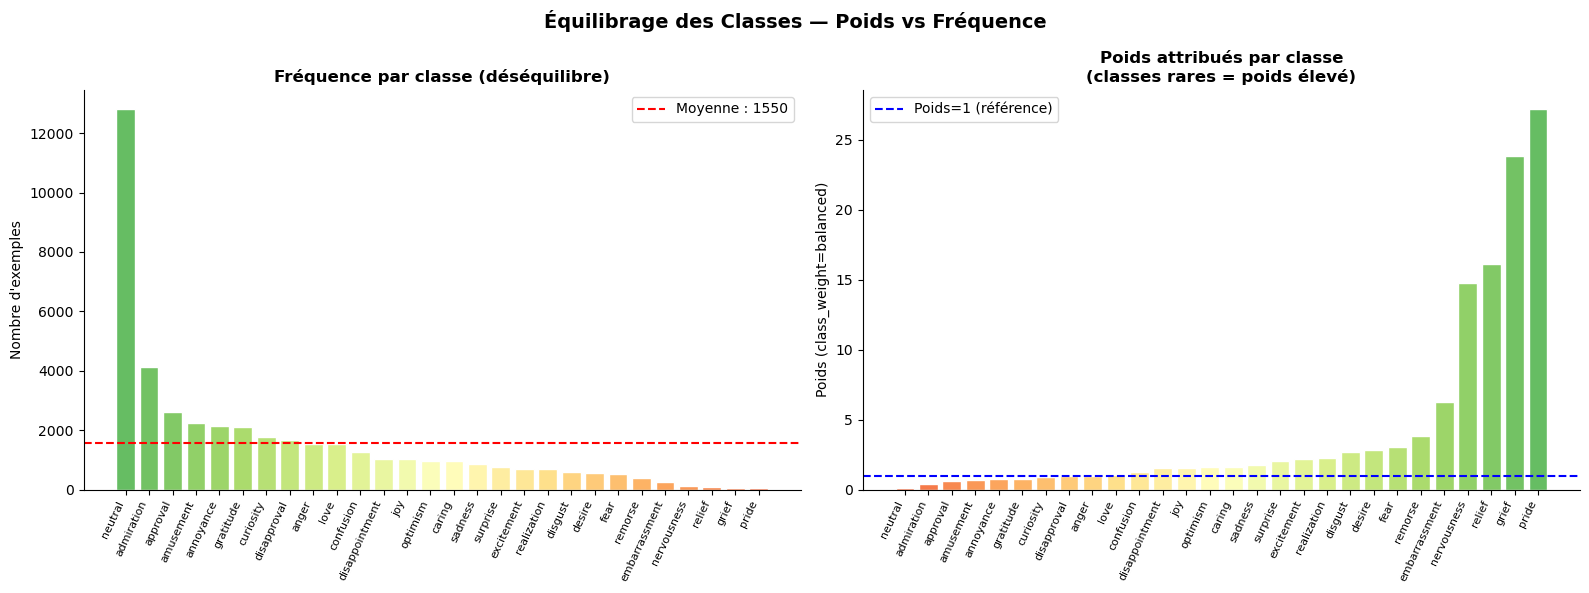

✅ Figure 6 sauvegardée — équilibrage des classes


In [4]:
# ── Visualisation des poids ───────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Équilibrage des Classes — Poids vs Fréquence',
             fontsize=14, fontweight='bold')

# Trier par fréquence (ordre du bar chart de l'EDA)
sorted_labels = sorted(class_weights_dict.keys(),
                       key=lambda l: (y_train==l).sum(), reverse=True)
emo_names = [emotion_mapping.get(l, str(l)) for l in sorted_labels]
counts    = [(y_train == l).sum() for l in sorted_labels]
weights   = [class_weights_dict[l] for l in sorted_labels]

# Panel gauche : fréquences
ax1 = axes[0]
colors_freq = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(sorted_labels))[::-1])
ax1.bar(range(len(emo_names)), counts, color=colors_freq, edgecolor='white')
ax1.set_xticks(range(len(emo_names)))
ax1.set_xticklabels(emo_names, rotation=65, ha='right', fontsize=8)
ax1.set_ylabel('Nombre d\'exemples')
ax1.set_title('Fréquence par classe (déséquilibre)', fontweight='bold')
ax1.axhline(np.mean(counts), color='red', linestyle='--',
            label=f'Moyenne : {np.mean(counts):.0f}')
ax1.legend()
ax1.spines[['top', 'right']].set_visible(False)

# Panel droit : poids (inversement proportionnels)
ax2 = axes[1]
colors_w = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(sorted_labels)))
ax2.bar(range(len(emo_names)), weights, color=colors_w, edgecolor='white')
ax2.set_xticks(range(len(emo_names)))
ax2.set_xticklabels(emo_names, rotation=65, ha='right', fontsize=8)
ax2.set_ylabel('Poids (class_weight=balanced)')
ax2.set_title('Poids attribués par classe\n(classes rares = poids élevé)', fontweight='bold')
ax2.axhline(1.0, color='blue', linestyle='--', label='Poids=1 (référence)')
ax2.legend()
ax2.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('fig6_class_weights.png', bbox_inches='tight')
plt.show()
print('✅ Figure 6 sauvegardée — équilibrage des classes')

## 7. Modélisation — 5 Algorithmes ML avec Équilibrage

Chaque modèle utilise `class_weight='balanced'` (ou équivalent) pour compenser le déséquilibre.

| # | Algorithme | Vectorisation | Équilibrage |
|---|---|---|---|
| 1 | Logistic Regression | TF-IDF | `class_weight='balanced'` |
| 2 | Multinomial Naive Bayes | CountVectorizer | poids manuels via `fit()` |
| 3 | Linear SVM | TF-IDF | `class_weight='balanced'` |
| 4 | Random Forest | LSA (300 dims) | `class_weight='balanced'` |
| 5 | KNN | LSA (300 dims) | `sample_weight` dans `fit()` |

In [5]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Imports des modèles + fonction d'évaluation
# ═══════════════════════════════════════════════════════════════


from sklearn.linear_model  import LogisticRegression
from sklearn.naive_bayes   import MultinomialNB
from sklearn.svm           import LinearSVC
from sklearn.ensemble      import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics       import (accuracy_score, f1_score, precision_score,
                                   recall_score, classification_report,
                                   confusion_matrix)

def evaluate_model(model, X_test, y_test, model_name='Modèle'):
    """
    Évalue un modèle entraîné sur le jeu de test.
    Retourne un dict avec toutes les métriques.
    """
    y_pred = model.predict(X_test)

    # Calcul des métriques
    acc      = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro',    zero_division=0)
    f1_w     = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    prec     = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec      = recall_score(y_test, y_pred,    average='macro', zero_division=0)

    # Noms des classes depuis emotion_mapping
    unique_labels = sorted(np.unique(np.concatenate([y_test, y_pred])))
    target_names  = [emotion_mapping.get(l, str(l)) for l in unique_labels]

    print(f'\n{"="*62}')
    print(f'  📊 {model_name}')
    print(f'{"="*62}')
    print(f'  Accuracy          : {acc:.4f}  ({acc*100:.2f}%)')
    print(f'  F1-Macro          : {f1_macro:.4f}  ← métrique principale')
    print(f'  F1-Weighted       : {f1_w:.4f}')
    print(f'  Precision (macro) : {prec:.4f}')
    print(f'  Recall (macro)    : {rec:.4f}')
    print(f'\n  Rapport par classe :')
    print(classification_report(y_test, y_pred,
                                 labels=unique_labels,
                                 target_names=target_names,
                                 zero_division=0))
    return {
        'Modèle'      : model_name,
        'Accuracy'    : round(acc,      4),
        'F1-Macro'    : round(f1_macro, 4),
        'F1-Weighted' : round(f1_w,     4),
        'Precision'   : round(prec,     4),
        'Recall'      : round(rec,      4),
        'y_pred'      : y_pred
    }

results_list = []
print('✅ Imports et fonction evaluate_model prêts')

✅ Imports et fonction evaluate_model prêts


In [6]:
# ═══════════════════════════════════════════════════════════════
# CELLULE DEBUG + FIX LABELS
# ═══════════════════════════════════════════════════════════════

print("=== DIAGNOSTIC ===")
print(f"y_train dtype     : {y_train.dtype}")
print(f"y_train shape     : {y_train.shape}")
print(f"classes uniques   : {np.unique(y_train)}")
print(f"nb classes        : {len(np.unique(y_train))}")
print(f"5 premiers        : {y_train[:5]}")
print(f"\ndf_train label dtype : {df_train['label'].dtype}")
print(f"df_train label head  :\n{df_train['label'].head(10)}")

=== DIAGNOSTIC ===
y_train dtype     : int64
y_train shape     : (43401,)
classes uniques   : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27]
nb classes        : 28
5 premiers        : [27 27  2 14  3]

df_train label dtype : int64
df_train label head  :
0    27
1    27
2     2
3    14
4     3
5    26
6    15
7     8
8     0
9    27
Name: label, dtype: int64


In [7]:
# ═══════════════════════════════════════════════════════════════
# MODÈLE 1 — Logistic Regression avec class_weight='balanced'
# ═══════════════════════════════════════════════════════════════
from sklearn.linear_model import LogisticRegression

print('⏳ [1/5] Logistic Regression + class_weight=balanced...')
t0 = time.time()

lr = LogisticRegression(
    C=1.0,
    solver='saga',
    max_iter=1000,
    class_weight='balanced',
    multi_class='multinomial',
    n_jobs=-1,
    random_state=42
)
lr.fit(X_train, y_train)
elapsed = time.time() - t0
print(f'   ✅ Entraîné en {elapsed:.1f}s')

res_lr = evaluate_model(lr, X_test, y_test, 'Logistic Regression (balanced)')
res_lr['Temps (s)'] = round(elapsed, 1)
results_list.append(res_lr)


⏳ [1/5] Logistic Regression + class_weight=balanced...


c:\Users\khali\anaconda3\envs\emotion\lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


   ✅ Entraîné en 117.8s

  📊 Logistic Regression (balanced)
  Accuracy          : 0.3432  (34.32%)
  F1-Macro          : 0.3317  ← métrique principale
  F1-Weighted       : 0.3513
  Precision (macro) : 0.3180
  Recall (macro)    : 0.4353

  Rapport par classe :
                precision    recall  f1-score   support

    admiration       0.53      0.35      0.42       504
     amusement       0.73      0.82      0.77       252
         anger       0.36      0.40      0.38       197
     annoyance       0.27      0.17      0.21       286
      approval       0.32      0.25      0.28       318
        caring       0.13      0.31      0.19       114
     confusion       0.18      0.32      0.23       139
     curiosity       0.19      0.17      0.18       233
        desire       0.24      0.34      0.28        74
disappointment       0.17      0.22      0.20       127
   disapproval       0.21      0.32      0.25       220
       disgust       0.32      0.54      0.40        84
 embarras

c:\Users\khali\anaconda3\envs\emotion\lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [8]:
# ═══════════════════════════════════════════════════════════════
# MODÈLE 2 — Naive Bayes avec sample_weight
# ═══════════════════════════════════════════════════════════════
# Note : on utilise TF-IDF (valeurs positives) compatible avec MultinomialNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import MinMaxScaler
import scipy.sparse as sp

print('⏳ [2/5] Naive Bayes + sample_weight...')
t0 = time.time()

# MinMaxScaler pour garantir des valeurs >= 0 (requis par MultinomialNB)
X_train_nb = sp.csr_matrix(X_train.toarray().clip(min=0))
X_test_nb  = sp.csr_matrix(X_test.toarray().clip(min=0))

sample_weights_train = np.array([class_weights_dict[label] for label in y_train])

nb = MultinomialNB(alpha=0.1)
nb.fit(X_train_nb, y_train, sample_weight=sample_weights_train)
elapsed = time.time() - t0
print(f'   ✅ Entraîné en {elapsed:.3f}s')

res_nb = evaluate_model(nb, X_test_nb, y_test, 'Naive Bayes (sample_weight)')
res_nb['Temps (s)'] = round(elapsed, 3)
results_list.append(res_nb)
gc.collect()


⏳ [2/5] Naive Bayes + sample_weight...
   ✅ Entraîné en 14.577s

  📊 Naive Bayes (sample_weight)
  Accuracy          : 0.2418  (24.18%)
  F1-Macro          : 0.2172  ← métrique principale
  F1-Weighted       : 0.2382
  Precision (macro) : 0.2028
  Recall (macro)    : 0.2994

  Rapport par classe :
                precision    recall  f1-score   support

    admiration       0.45      0.35      0.40       504
     amusement       0.50      0.49      0.49       252
         anger       0.25      0.30      0.27       197
     annoyance       0.18      0.17      0.18       286
      approval       0.23      0.18      0.20       318
        caring       0.14      0.28      0.18       114
     confusion       0.09      0.17      0.12       139
     curiosity       0.13      0.12      0.13       233
        desire       0.12      0.23      0.16        74
disappointment       0.12      0.22      0.16       127
   disapproval       0.18      0.20      0.19       220
       disgust       0.18   

44

In [9]:
# ═══════════════════════════════════════════════════════════════
# MODÈLE 3 — Linear SVM avec class_weight='balanced'
# ═══════════════════════════════════════════════════════════════
#
# PRINCIPE :
#   Le SVM (Support Vector Machine) cherche l'hyperplan qui sépare
#   les classes avec la MARGE MAXIMALE. La marge est la distance
#   entre l'hyperplan et les exemples les plus proches (vecteurs
#   supports).
#   LinearSVC est optimisé pour les données sparse haute dimension
#   (comme TF-IDF) → plus rapide que SVC(kernel='linear').
#
# class_weight='balanced' :
#   Multiplie C (pénalité de mauvaise classification) par le poids
#   de chaque classe. Les erreurs sur les classes rares sont plus
#   pénalisées → le modèle fait plus d'efforts pour les apprendre.
#
# C=1.0 : pénalité pour les points mal classifiés
#   Grand C → marge plus petite, modèle plus strict
#   Petit C → marge plus grande, plus de tolérance aux erreurs

print('⏳ [3/5] Linear SVM + class_weight=balanced...')
t0 = time.time()

svm = LinearSVC(
    C=1.0,
    max_iter=2000,
    class_weight='balanced',    # ← ÉQUILIBRAGE
    random_state=42
)
svm.fit(X_train, y_train)
elapsed = time.time() - t0
print(f'   ✅ Entraîné en {elapsed:.1f}s')

res_svm = evaluate_model(svm, X_test, y_test, ...)
res_svm['Temps (s)'] = round(elapsed, 1)
results_list.append(res_svm)

⏳ [3/5] Linear SVM + class_weight=balanced...
   ✅ Entraîné en 6.0s

  📊 Ellipsis
  Accuracy          : 0.3574  (35.74%)
  F1-Macro          : 0.3200  ← métrique principale
  F1-Weighted       : 0.3566
  Precision (macro) : 0.2882
  Recall (macro)    : 0.3941

  Rapport par classe :
                precision    recall  f1-score   support

    admiration       0.52      0.43      0.47       504
     amusement       0.67      0.77      0.71       252
         anger       0.30      0.41      0.34       197
     annoyance       0.26      0.19      0.22       286
      approval       0.28      0.20      0.24       318
        caring       0.18      0.33      0.23       114
     confusion       0.16      0.28      0.21       139
     curiosity       0.15      0.12      0.13       233
        desire       0.19      0.34      0.25        74
disappointment       0.17      0.27      0.21       127
   disapproval       0.23      0.28      0.25       220
       disgust       0.26      0.43      0.

In [10]:
# ═══════════════════════════════════════════════════════════════
# MODÈLE 4 — Random Forest avec class_weight='balanced_subsample'
# ═══════════════════════════════════════════════════════════════
from sklearn.ensemble import RandomForestClassifier

print('⏳ [4/5] Random Forest + class_weight=balanced_subsample...')
print('   (peut prendre 2-4 minutes)')
t0 = time.time()

rf = RandomForestClassifier(
    n_estimators=100,           # réduit pour la vitesse
    max_depth=30,               # limite profondeur
    min_samples_leaf=2,
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=42
)
rf.fit(X_train, y_train)
elapsed = time.time() - t0
print(f'   ✅ Entraîné en {elapsed:.1f}s')

res_rf = evaluate_model(rf, X_test, y_test, 'Random Forest (balanced_subsample)')
res_rf['Temps (s)'] = round(elapsed, 1)
results_list.append(res_rf)
gc.collect()


⏳ [4/5] Random Forest + class_weight=balanced_subsample...
   (peut prendre 2-4 minutes)
   ✅ Entraîné en 1.9s

  📊 Random Forest (balanced_subsample)
  Accuracy          : 0.3976  (39.76%)
  F1-Macro          : 0.3217  ← métrique principale
  F1-Weighted       : 0.3860
  Precision (macro) : 0.3935
  Recall (macro)    : 0.4035

  Rapport par classe :
                precision    recall  f1-score   support

    admiration       0.67      0.20      0.30       504
     amusement       0.74      0.75      0.75       252
         anger       0.47      0.31      0.37       197
     annoyance       0.50      0.01      0.02       286
      approval       0.37      0.07      0.12       318
        caring       0.41      0.06      0.11       114
     confusion       0.31      0.13      0.18       139
     curiosity       0.70      0.03      0.06       233
        desire       0.42      0.27      0.33        74
disappointment       0.24      0.09      0.14       127
   disapproval       0.14     

58

In [11]:
# ═══════════════════════════════════════════════════════════════
# MODÈLE 5 — k-Nearest Neighbors
# ═══════════════════════════════════════════════════════════════
from sklearn.neighbors import KNeighborsClassifier

print('⏳ [5/5] k-NN (k=7)...')
t0 = time.time()

knn = KNeighborsClassifier(
    n_neighbors=7,
    metric='cosine',
    n_jobs=-1
)
knn.fit(X_train, y_train)
elapsed = time.time() - t0
print(f'   ✅ Entraîné en {elapsed:.1f}s')

res_knn = evaluate_model(knn, X_test, y_test, 'k-Nearest Neighbors (k=7)')
res_knn['Temps (s)'] = round(elapsed, 1)
results_list.append(res_knn)
gc.collect()


⏳ [5/5] k-NN (k=7)...
   ✅ Entraîné en 0.0s

  📊 k-Nearest Neighbors (k=7)
  Accuracy          : 0.3629  (36.29%)
  F1-Macro          : 0.2510  ← métrique principale
  F1-Weighted       : 0.3276
  Precision (macro) : 0.3278
  Recall (macro)    : 0.2242

  Rapport par classe :
                precision    recall  f1-score   support

    admiration       0.33      0.45      0.38       504
     amusement       0.36      0.41      0.38       252
         anger       0.27      0.29      0.28       197
     annoyance       0.25      0.12      0.17       286
      approval       0.18      0.10      0.13       318
        caring       0.30      0.23      0.26       114
     confusion       0.19      0.09      0.13       139
     curiosity       0.12      0.06      0.08       233
        desire       0.38      0.11      0.17        74
disappointment       0.27      0.05      0.08       127
   disapproval       0.18      0.07      0.10       220
       disgust       0.46      0.29      0.35     

58

## 8. Évaluation et Comparaison des Modèles

In [12]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Tableau comparatif des 5 modèles
# ═══════════════════════════════════════════════════════════════

metrics_cols = ['Modèle', 'Accuracy', 'F1-Macro', 'F1-Weighted',
                'Precision', 'Recall', 'Temps (s)']

df_results = (pd.DataFrame(results_list)[metrics_cols]
              .sort_values('F1-Macro', ascending=False)
              .reset_index(drop=True))
df_results.index += 1

print('\n' + '═'*80)
print('              📊 TABLEAU COMPARATIF — 5 MODÈLES ML AVEC ÉQUILIBRAGE')
print('═'*80)
print(df_results.to_string())
print('═'*80)
print(f'\n🏆 Meilleur modèle : {df_results.iloc[0]["Modèle"]}')
print(f'   F1-Macro : {df_results.iloc[0]["F1-Macro"]:.4f}')
print(f'   Accuracy : {df_results.iloc[0]["Accuracy"]:.4f}')


════════════════════════════════════════════════════════════════════════════════
              📊 TABLEAU COMPARATIF — 5 MODÈLES ML AVEC ÉQUILIBRAGE
════════════════════════════════════════════════════════════════════════════════
                               Modèle  Accuracy  F1-Macro  F1-Weighted  Precision  Recall  Temps (s)
1      Logistic Regression (balanced)    0.3432    0.3317       0.3513     0.3180  0.4353    117.800
2  Random Forest (balanced_subsample)    0.3976    0.3217       0.3860     0.3935  0.4035      1.900
3                            Ellipsis    0.3574    0.3200       0.3566     0.2882  0.3941      6.000
4           k-Nearest Neighbors (k=7)    0.3629    0.2510       0.3276     0.3278  0.2242      0.000
5         Naive Bayes (sample_weight)    0.2418    0.2172       0.2382     0.2028  0.2994     14.577
════════════════════════════════════════════════════════════════════════════════

🏆 Meilleur modèle : Logistic Regression (balanced)
   F1-Macro : 0.3317
   Accurac

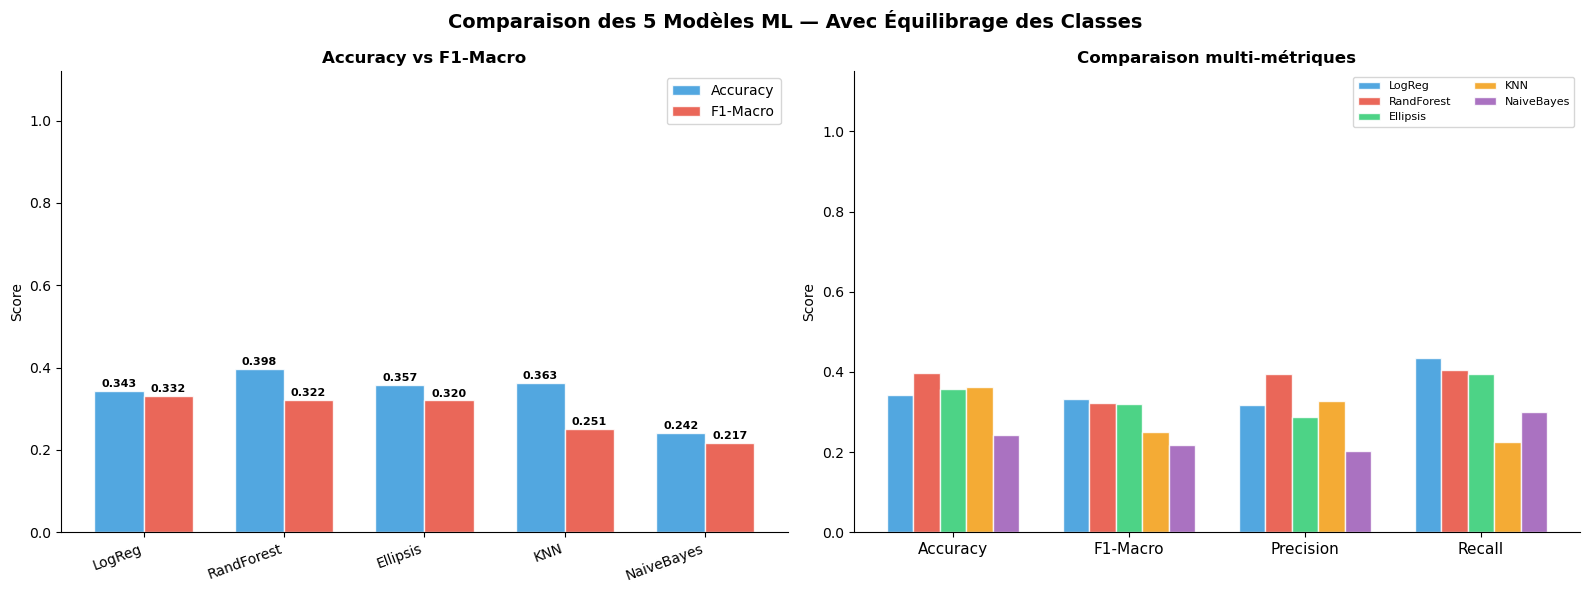

✅ Figure 7 sauvegardée


In [13]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Graphiques de comparaison des 5 modèles
# ═══════════════════════════════════════════════════════════════

name_to_short = {
    'Logistic Regression (balanced)'        : 'LogReg',
    'Naive Bayes (sample_weight)'           : 'NaiveBayes',
    'Linear SVM (balanced)'                 : 'SVM',
    'Random Forest (balanced_subsample)'    : 'RandForest',
    'k-Nearest Neighbors (k=7)'             : 'KNN'
}

model_names = df_results['Modèle'].tolist()
x_labels    = [name_to_short.get(n, n) for n in model_names]
palette     = ['#3498DB', '#E74C3C', '#2ECC71', '#F39C12', '#9B59B6']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Comparaison des 5 Modèles ML — Avec Équilibrage des Classes',
             fontsize=14, fontweight='bold')

ax = axes[0]
x, w = np.arange(len(model_names)), 0.35
b1 = ax.bar(x - w/2, df_results['Accuracy'], w,
            label='Accuracy', color='#3498DB', alpha=0.85, edgecolor='white')
b2 = ax.bar(x + w/2, df_results['F1-Macro'],  w,
            label='F1-Macro', color='#E74C3C', alpha=0.85, edgecolor='white')
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.004,
            f'{b.get_height():.3f}', ha='center', va='bottom',
            fontsize=8, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(x_labels, rotation=20, ha='right')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.12)
ax.legend()
ax.set_title('Accuracy vs F1-Macro', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)

ax2 = axes[1]
metrics4 = ['Accuracy', 'F1-Macro', 'Precision', 'Recall']
x2, n, bw = np.arange(len(metrics4)), len(model_names), 0.15
for i, (mod, color) in enumerate(zip(model_names, palette)):
    row  = df_results[df_results['Modèle'] == mod].iloc[0]
    vals = [row[m] for m in metrics4]
    ax2.bar(x2 + (i - n/2 + 0.5)*bw, vals, bw,
            label=name_to_short.get(mod, mod),
            color=color, alpha=0.85, edgecolor='white')
ax2.set_xticks(x2)
ax2.set_xticklabels(metrics4, fontsize=11)
ax2.set_ylim(0, 1.15)
ax2.set_ylabel('Score')
ax2.set_title('Comparaison multi-métriques', fontweight='bold')
ax2.legend(fontsize=8, ncol=2)
ax2.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('fig7_comparaison_5modeles.png', bbox_inches='tight')
plt.show()
print('✅ Figure 7 sauvegardée')


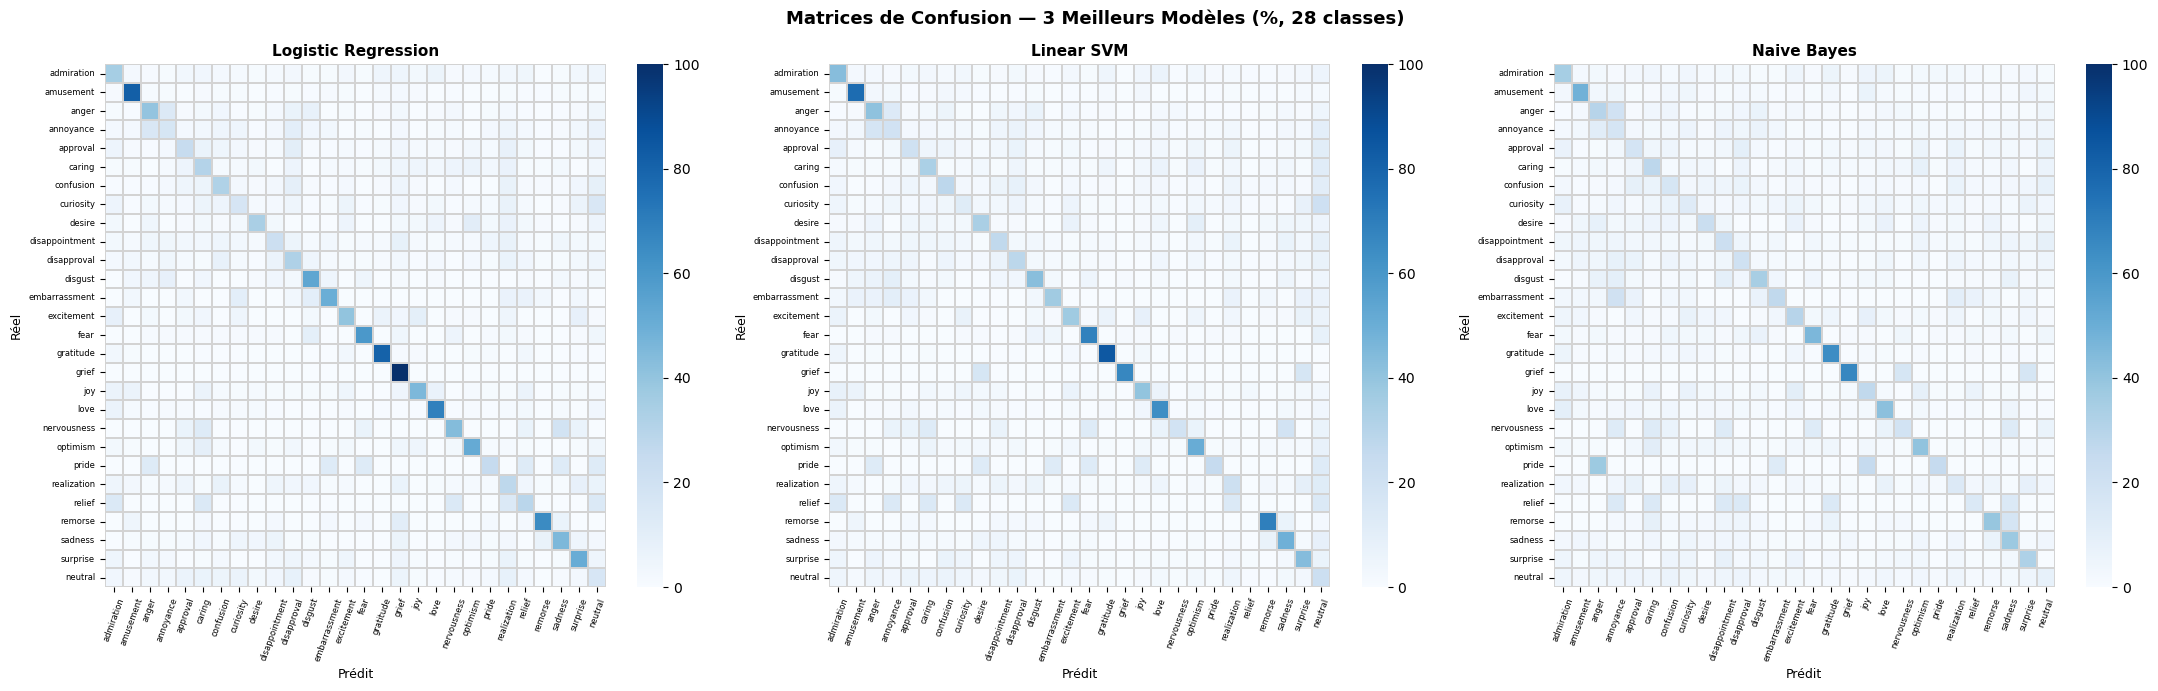

✅ Figure 8 sauvegardée


In [14]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Matrices de confusion — 3 meilleurs modèles
# ═══════════════════════════════════════════════════════════════

unique_test_labels = sorted(np.unique(y_test))
label_names_cm     = [emotion_mapping.get(l, str(l)) for l in unique_test_labels]

models_for_cm = [
    ('Logistic Regression', lr,  X_test),
    ('Linear SVM',          svm, X_test),
    ('Naive Bayes',         nb,  X_test_nb),
]

fig, axes = plt.subplots(1, 3, figsize=(22, 7))
fig.suptitle('Matrices de Confusion — 3 Meilleurs Modèles (%, 28 classes)',
             fontsize=13, fontweight='bold')

for ax, (name, model, X_t) in zip(axes, models_for_cm):
    y_pred = model.predict(X_t)
    cm     = confusion_matrix(y_test, y_pred, labels=unique_test_labels)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    sns.heatmap(cm_pct, annot=False, cmap='Blues',
                xticklabels=label_names_cm, yticklabels=label_names_cm,
                ax=ax, cbar=True, linewidths=0.1, linecolor='lightgray',
                vmin=0, vmax=100)
    ax.set_title(name, fontweight='bold', fontsize=11)
    ax.set_xlabel('Prédit', fontsize=9)
    ax.set_ylabel('Réel', fontsize=9)
    ax.tick_params(axis='x', rotation=70, labelsize=6)
    ax.tick_params(axis='y', rotation=0,  labelsize=6)

plt.tight_layout()
plt.savefig('fig8_confusion_matrices.png', bbox_inches='tight')
plt.show()
print('✅ Figure 8 sauvegardée')

## 9. Optimisation du Meilleur Modèle (GridSearchCV)

In [15]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : GridSearchCV sur Linear SVM
# ═══════════════════════════════════════════════════════════════




from sklearn.model_selection import GridSearchCV

print('⏳ GridSearchCV sur Linear SVM (validation croisée 3-fold)...')
t0 = time.time()

param_grid = {
    'C'       : [0.01, 0.1, 1.0, 5.0, 10.0],
    'max_iter': [2000]
}

grid_search = GridSearchCV(
    LinearSVC(class_weight='balanced', random_state=42),
    param_grid,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)

print(f'\n✅ Terminé en {time.time()-t0:.1f}s')
print(f'   Meilleurs paramètres   : {grid_search.best_params_}')
print(f'   Meilleur F1-Macro (CV) : {grid_search.best_score_:.4f}')

best_svm = grid_search.best_estimator_
res_best = evaluate_model(best_svm, X_test, y_test,
                          'SVM Optimisé GridSearch (balanced)')
print(f'\n🏆 SVM optimisé — Performance finale sur Test Set :')
print(f'   F1-Macro : {res_best["F1-Macro"]:.4f}')
print(f'   Accuracy : {res_best["Accuracy"]:.4f}')

⏳ GridSearchCV sur Linear SVM (validation croisée 3-fold)...
Fitting 3 folds for each of 5 candidates, totalling 15 fits

✅ Terminé en 39.5s
   Meilleurs paramètres   : {'C': 0.01, 'max_iter': 2000}
   Meilleur F1-Macro (CV) : 0.3250

  📊 SVM Optimisé GridSearch (balanced)
  Accuracy          : 0.3900  (39.00%)
  F1-Macro          : 0.3444  ← métrique principale
  F1-Weighted       : 0.4018
  Precision (macro) : 0.3433
  Recall (macro)    : 0.4592

  Rapport par classe :
                precision    recall  f1-score   support

    admiration       0.57      0.36      0.44       504
     amusement       0.74      0.80      0.77       252
         anger       0.40      0.44      0.42       197
     annoyance       0.48      0.10      0.17       286
      approval       0.44      0.22      0.29       318
        caring       0.23      0.30      0.26       114
     confusion       0.27      0.27      0.27       139
     curiosity       0.36      0.07      0.12       233
        desire     

## 10. Prédictions sur de Nouveaux Textes

In [16]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Pipeline complet de prédiction
# ═══════════════════════════════════════════════════════════════
import re

# Copie de preprocess_text (évite le problème d'import src)
CONTRACTIONS = {
    "won't": "will not", "can't": "cannot", "don't": "do not",
    "it's": "it is", "i'm": "i am", "you're": "you are",
    "they're": "they are", "we're": "we are", "that's": "that is",
    "what's": "what is", "who's": "who is", "there's": "there is",
    "here's": "here is", "he's": "he is", "she's": "she is",
    "how's": "how is", "where's": "where is", "when's": "when is",
    "n't": " not", "'re": " are", "'s": " is", "'d": " would",
    "'ll": " will", "'ve": " have", "'m": " am",
}

def preprocess_text(text: str) -> str:
    if not isinstance(text, str) or text.strip() == '':
        return ''
    text = text.lower().replace('\u2019', "'")
    for contraction, expansion in CONTRACTIONS.items():
        text = re.sub(re.escape(contraction), expansion, text)
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'@\w+|#\w+|r/\w+|u/\w+', '', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r"[^a-z\s']", ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def predict_emotion(texts, model=best_svm, vectorizer=tfidf):
    cleaned = [preprocess_text(t) for t in texts]
    X       = vectorizer.transform(cleaned)
    preds   = model.predict(X)
    return pd.DataFrame({
        'Texte Original' : texts,
        'Texte Nettoyé'  : cleaned,
        'Label'          : preds,
        'Émotion Prédite': [emotion_mapping.get(p, str(p)) for p in preds]
    })

new_texts = [
    "I absolutely love this! It made my day so much better!",
    "This is the worst experience ever. I'm furious at this system!",
    "The package arrived today. It contains 3 items.",
    "I'm so disappointed, I was really hoping for more.",
    "Wow, this is incredibly awesome! Thank you so much!",
    "I feel terrible about what happened, I regret everything.",
    "I hate waiting in long lines, it makes me so angry.",
    "Haha that's actually really funny, I can't stop laughing!",
    "I'm scared of what might happen next.",
    "The weather is nice today, nothing special.",
]

predictions = predict_emotion(new_texts)

print('\n🎭 PRÉDICTIONS SUR DE NOUVEAUX TEXTES :')
print('═' * 72)
for _, row in predictions.iterrows():
    print(f"  {row['Émotion Prédite']:<18} | {row['Texte Original'][:55]}")
print('═' * 72)


🎭 PRÉDICTIONS SUR DE NOUVEAUX TEXTES :
════════════════════════════════════════════════════════════════════════
  love               | I absolutely love this! It made my day so much better!
  disgust            | This is the worst experience ever. I'm furious at this 
  neutral            | The package arrived today. It contains 3 items.
  optimism           | I'm so disappointed, I was really hoping for more.
  gratitude          | Wow, this is incredibly awesome! Thank you so much!
  remorse            | I feel terrible about what happened, I regret everythin
  anger              | I hate waiting in long lines, it makes me so angry.
  amusement          | Haha that's actually really funny, I can't stop laughin
  fear               | I'm scared of what might happen next.
  admiration         | The weather is nice today, nothing special.
════════════════════════════════════════════════════════════════════════


In [17]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Sauvegarde du modèle et du vectoriseur dans models/
# ═══════════════════════════════════════════════════════════════

import joblib, os
os.makedirs('models', exist_ok=True)

joblib.dump(best_svm, 'models/best_svm.joblib')
joblib.dump(tfidf,    'models/tfidf_vectorizer.joblib')

print('✅ Modèle sauvegardé     : models/best_svm.joblib')
print('✅ Vectoriseur sauvegardé: models/tfidf_vectorizer.joblib')
print()
print('Pour recharger :')
print("  import joblib")
print("  model = joblib.load('models/best_svm.joblib')")
print("  tfidf = joblib.load('models/tfidf_vectorizer.joblib')")


✅ Modèle sauvegardé     : models/best_svm.joblib
✅ Vectoriseur sauvegardé: models/tfidf_vectorizer.joblib

Pour recharger :
  import joblib
  model = joblib.load('models/best_svm.joblib')
  tfidf = joblib.load('models/tfidf_vectorizer.joblib')
